In [1]:
# Import libraries
import pandas as pd
from pathlib import Path

# Set project folder location
project_folder = Path(
    r"C:\DataAnalytics\Marketplace-Intelligence"
)

# Load prepared dataset
model_data = pd.read_csv(
    project_folder / "data" / "processed" /
    "delivery_model_data.csv",
    parse_dates=["order_purchase_timestamp"]
)

print("Model dataset loaded successfully!")

print("Dataset dimensions:", model_data.shape)

# Display first 5 rows
model_data.head()

Model dataset loaded successfully!
Dataset dimensions: (96470, 8)


,order_id,is_cross_state,number_of_sellers,delivery_route,is_late,delivery_days,customer_state,order_purchase_timestamp
0,00010242fe8c5a6d1ba2dd792cb16214,True,1,Cross State,False,7.614421,RJ,2017-09-13 08:59:02
1,00018f77f2f0320c557190d7a144bdd3,False,1,Same State,False,16.216181,SP,2017-04-26 10:53:06
2,000229ec398224ef6ca0657da4fc703e,False,1,Same State,False,7.948437,MG,2018-01-14 14:33:31
3,00024acbcdf0a6daa1e931b038114c75,False,1,Same State,False,6.147269,SP,2018-08-08 10:00:35
4,00042b26cf59d7ce69dfabb4e55b4fd9,True,1,Cross State,False,25.114352,SP,2017-02-04 13:57:51


In [2]:
# Display column names and data types

print("Column names:")
print(model_data.columns.tolist())

print("\nData types:")
print(model_data.dtypes)

Column names:
['order_id', 'is_cross_state', 'number_of_sellers', 'delivery_route', 'is_late', 'delivery_days', 'customer_state', 'order_purchase_timestamp']

Data types:
order_id                               str
is_cross_state                        bool
number_of_sellers                    int64
delivery_route                         str
is_late                               bool
delivery_days                      float64
customer_state                         str
order_purchase_timestamp    datetime64[us]
dtype: object


In [3]:
# Check the dataset before modelling

required_columns = [
    "order_id",
    "is_cross_state",
    "is_late",
    "customer_state",
    "order_purchase_timestamp"
]

print("Missing values:")
print(model_data[required_columns].isnull().sum())

print("\nDuplicate order IDs:")
print(model_data["order_id"].duplicated().sum())

print("\nLate delivery outcomes:")
print(model_data["is_late"].value_counts())

Missing values:
order_id                    0
is_cross_state              0
is_late                     0
customer_state              0
order_purchase_timestamp    0
dtype: int64

Duplicate order IDs:
0

Late delivery outcomes:
is_late
False    88644
True      7826
Name: count, dtype: int64


In [4]:
# Create a copy for modelling
model_ready = model_data.copy()

print("Modelling dataset created!")
print("Total records:", len(model_ready))

Modelling dataset created!
Total records: 96470


In [5]:
# Convert Boolean variables into numeric values

model_ready["late_target"] = (
    model_ready["is_late"].astype(int)
)

model_ready["cross_state_numeric"] = (
    model_ready["is_cross_state"].astype(int)
)

# Display the results
model_ready[
    [
        "is_late",
        "late_target",
        "is_cross_state",
        "cross_state_numeric"
    ]
].head(10)

,is_late,late_target,is_cross_state,cross_state_numeric
0,False,0,True,1
1,False,0,False,0
2,False,0,False,0
3,False,0,False,0
4,False,0,True,1
5,False,0,True,1
6,False,0,False,0
7,False,0,False,0
8,True,1,False,0
9,False,0,False,0


In [6]:
# Extract month from purchase date

model_ready["purchase_month"] = (
    model_ready["order_purchase_timestamp"].dt.month
)

print("Purchase months created!")

model_ready[
    [
        "order_purchase_timestamp",
        "purchase_month"
    ]
].head(10)

Purchase months created!


,order_purchase_timestamp,purchase_month
0,2017-09-13 08:59:02,9
1,2017-04-26 10:53:06,4
2,2018-01-14 14:33:31,1
3,2018-08-08 10:00:35,8
4,2017-02-04 13:57:51,2
5,2017-05-15 21:42:34,5
6,2017-12-10 11:53:48,12
7,2018-07-04 12:08:27,7
8,2018-03-19 18:40:33,3
9,2018-07-02 13:59:39,7


In [7]:
# Check prepared modelling variables

prepared_columns = [
    "late_target",
    "cross_state_numeric",
    "customer_state",
    "purchase_month"
]

print("First 10 records:")
display(model_ready[prepared_columns].head(10))

print("\nMissing values:")
print(model_ready[prepared_columns].isnull().sum())

print("\nData types:")
print(model_ready[prepared_columns].dtypes)

First 10 records:


,late_target,cross_state_numeric,customer_state,purchase_month
0,0,1,RJ,9
1,0,0,SP,4
2,0,0,MG,1
3,0,0,SP,8
4,0,1,SP,2
5,0,1,MG,5
6,0,0,SP,12
7,0,0,SP,7
8,1,0,SP,3
9,0,0,SP,7



Missing values:
late_target            0
cross_state_numeric    0
customer_state         0
purchase_month         0
dtype: int64

Data types:
late_target            int64
cross_state_numeric    int64
customer_state           str
purchase_month         int32
dtype: object


In [8]:
# Sort orders from oldest to newest

model_sorted = model_ready.sort_values(
    by="order_purchase_timestamp"
).reset_index(drop=True)

print("Total orders:", len(model_sorted))

print(
    "Earliest purchase:",
    model_sorted["order_purchase_timestamp"].min()
)

print(
    "Latest purchase:",
    model_sorted["order_purchase_timestamp"].max()
)

Total orders: 96470
Earliest purchase: 2016-09-15 12:16:38
Latest purchase: 2018-08-29 15:00:37


In [9]:
# Calculate the splitting position

split_index = int(len(model_sorted) * 0.80)

# Split chronologically
train_data = model_sorted.iloc[:split_index].copy()
test_data = model_sorted.iloc[split_index:].copy()

print("Training records:", len(train_data))
print("Testing records:", len(test_data))
print("Total records:", len(train_data) + len(test_data))

Training records: 77176
Testing records: 19294
Total records: 96470


In [10]:
# Check the date ranges

print("TRAINING PERIOD")
print("Start:", train_data["order_purchase_timestamp"].min())
print("End:", train_data["order_purchase_timestamp"].max())

print("\nTESTING PERIOD")
print("Start:", test_data["order_purchase_timestamp"].min())
print("End:", test_data["order_purchase_timestamp"].max())

TRAINING PERIOD
Start: 2016-09-15 12:16:38
End: 2018-05-26 18:16:57

TESTING PERIOD
Start: 2018-05-26 18:18:03
End: 2018-08-29 15:00:37


In [11]:
# Compare late delivery rates

print("TRAINING DATA")
print("Total orders:", len(train_data))
print("Late orders:", train_data["late_target"].sum())
print(
    "Late rate:",
    round(train_data["late_target"].mean() * 100, 2),
    "%"
)

print("\nTESTING DATA")
print("Total orders:", len(test_data))
print("Late orders:", test_data["late_target"].sum())
print(
    "Late rate:",
    round(test_data["late_target"].mean() * 100, 2),
    "%"
)

TRAINING DATA
Total orders: 77176
Late orders: 6805
Late rate: 8.82 %

TESTING DATA
Total orders: 19294
Late orders: 1021
Late rate: 5.29 %


In [13]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)
print("Scikit-learn is ready!")

Scikit-learn version: 1.9.1
Scikit-learn is ready!


In [14]:
# Select predictor columns
feature_columns = [
    "cross_state_numeric",
    "customer_state",
    "purchase_month"
]

# Create training predictors (X)
X_train = train_data[feature_columns].copy()

# Create training target (y)
y_train = train_data["late_target"].copy()

print("Training predictors:", X_train.shape)
print("Training target:", y_train.shape)

display(X_train.head())

Training predictors: (77176, 3)
Training target: (77176,)


,cross_state_numeric,customer_state,purchase_month
0,1,SP,9
1,1,SP,10
2,1,RS,10
3,1,RS,10
4,0,SP,10


In [15]:
# Create testing predictors (X)
X_test = test_data[feature_columns].copy()

# Create testing target (y)
y_test = test_data["late_target"].copy()

print("Testing predictors:", X_test.shape)
print("Testing target:", y_test.shape)

display(X_test.head())

Testing predictors: (19294, 3)
Testing target: (19294,)


,cross_state_numeric,customer_state,purchase_month
77176,0,SP,5
77177,0,SP,5
77178,0,SP,5
77179,1,MG,5
77180,0,SP,5


In [16]:
# Check late and on-time delivery counts

print("TRAINING OUTCOMES")
print(y_train.value_counts())

print("\nTESTING OUTCOMES")
print(y_test.value_counts())

TRAINING OUTCOMES
late_target
0    70371
1     6805
Name: count, dtype: int64

TESTING OUTCOMES
late_target
0    18273
1     1021
Name: count, dtype: int64


In [17]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

print("Model libraries imported successfully!")

Model libraries imported successfully!


In [18]:
# Create copies of the predictors

X_train_model = X_train.copy()
X_test_model = X_test.copy()

# Convert month numbers into categorical strings

X_train_model["purchase_month"] = (
    X_train_model["purchase_month"].astype(str)
)

X_test_model["purchase_month"] = (
    X_test_model["purchase_month"].astype(str)
)

print("Predictor variables prepared!")

display(X_train_model.head())

Predictor variables prepared!


,cross_state_numeric,customer_state,purchase_month
0,1,SP,9
1,1,SP,10
2,1,RS,10
3,1,RS,10
4,0,SP,10


In [19]:
# Define categorical and numerical predictors

categorical_features = [
    "customer_state",
    "purchase_month"
]

numerical_features = [
    "cross_state_numeric"
]

# Create data preprocessor

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("Data preprocessor created successfully!")

Data preprocessor created successfully!


In [20]:
# Combine preprocessing and logistic regression

logistic_model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

print("Logistic Regression pipeline created!")

Logistic Regression pipeline created!


In [21]:
# Train the Logistic Regression model

logistic_model.fit(
    X_train_model,
    y_train
)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [22]:
# Check the number of features after encoding

feature_names = logistic_model.named_steps[
    "preprocessing"
].get_feature_names_out()

print("Number of model features:", len(feature_names))

print("\nFirst 15 features:")
print(feature_names[:15])

Number of model features: 40

First 15 features:
['categorical__customer_state_AC' 'categorical__customer_state_AL'
 'categorical__customer_state_AM' 'categorical__customer_state_AP'
 'categorical__customer_state_BA' 'categorical__customer_state_CE'
 'categorical__customer_state_DF' 'categorical__customer_state_ES'
 'categorical__customer_state_GO' 'categorical__customer_state_MA'
 'categorical__customer_state_MG' 'categorical__customer_state_MS'
 'categorical__customer_state_MT' 'categorical__customer_state_PA'
 'categorical__customer_state_PB']


In [23]:
# Predict delivery outcomes on the testing dataset

y_pred = logistic_model.predict(X_test_model)

# Predict probability of late delivery
y_prob = logistic_model.predict_proba(X_test_model)[:, 1]

print("Predictions completed successfully!")

print("Total predictions:", len(y_pred))

print("Predicted on-time orders:", (y_pred == 0).sum())

print("Predicted late orders:", (y_pred == 1).sum())

Predictions completed successfully!
Total predictions: 19294
Predicted on-time orders: 19294
Predicted late orders: 0


In [24]:
# Compare actual and predicted delivery outcomes

prediction_results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred,
    "Late_Probability": y_prob
})

prediction_results.head(10)

,Actual,Predicted,Late_Probability
0,0,0,0.041155
1,0,0,0.041155
2,0,0,0.041155
3,0,0,0.052751
4,0,0,0.041155
5,1,0,0.139471
6,0,0,0.041155
7,0,0,0.132173
8,0,0,0.046570
9,0,0,0.094589


In [25]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")

print("Accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("Precision:",
      round(precision_score(y_test, y_pred, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, y_pred, zero_division=0), 4))

print("F1-score:",
      round(f1_score(y_test, y_pred, zero_division=0), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_prob), 4))

print("Average Precision:",
      round(average_precision_score(y_test, y_prob), 4))

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy: 0.9471
Precision: 0.0
Recall: 0.0
F1-score: 0.0
ROC-AUC: 0.3365
Average Precision: 0.0442


In [26]:
from sklearn.dummy import DummyClassifier

# Create a simple baseline model
baseline_model = DummyClassifier(strategy="prior")

# Train baseline on training data
baseline_model.fit(X_train_model, y_train)

# Test baseline
baseline_pred = baseline_model.predict(X_test_model)
baseline_prob = baseline_model.predict_proba(X_test_model)[:, 1]

print("BASELINE MODEL RESULTS")
print("----------------------")

print("Accuracy:",
      round(accuracy_score(y_test, baseline_pred), 4))

print("Recall:",
      round(recall_score(y_test, baseline_pred, zero_division=0), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, baseline_prob), 4))

print("Average Precision:",
      round(average_precision_score(y_test, baseline_prob), 4))

BASELINE MODEL RESULTS
----------------------
Accuracy: 0.9471
Recall: 0.0
ROC-AUC: 0.5
Average Precision: 0.0529


In [27]:
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix for Logistic Regression
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

print("LOGISTIC REGRESSION CONFUSION MATRIX")
print(cm)

# Extract individual values
tn, fp, fn, tp = cm.ravel()

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

LOGISTIC REGRESSION CONFUSION MATRIX
[[18273     0]
 [ 1021     0]]

True Negatives: 18273
False Positives: 0
False Negatives: 1021
True Positives: 0


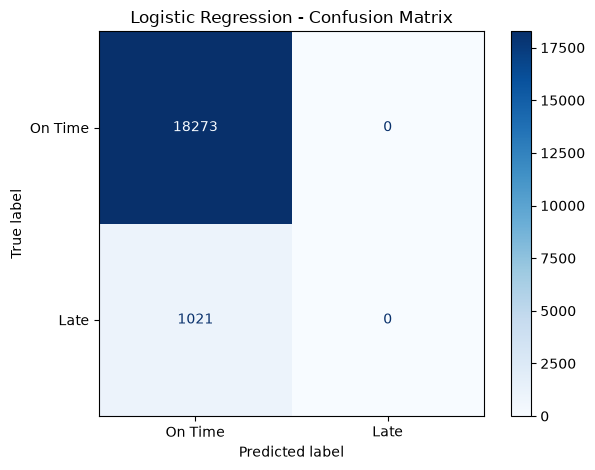

In [28]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["On Time", "Late"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

In [29]:
print("LOGISTIC REGRESSION PERFORMANCE")
print("--------------------------------")

print("Accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("Precision:",
      round(precision_score(y_test, y_pred, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, y_pred, zero_division=0), 4))

print("F1-score:",
      round(f1_score(y_test, y_pred, zero_division=0), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_prob), 4))

print("Average Precision:",
      round(average_precision_score(y_test, y_prob), 4))

LOGISTIC REGRESSION PERFORMANCE
--------------------------------
Accuracy: 0.9471
Precision: 0.0
Recall: 0.0
F1-score: 0.0
ROC-AUC: 0.3365
Average Precision: 0.0442


In [30]:
# Investigate model predictions

print("MODEL PREDICTION DIAGNOSTICS")
print("----------------------------")

print("Model classes:",
      logistic_model.named_steps["classifier"].classes_)

print("Minimum probability:", round(y_prob.min(), 4))
print("Maximum probability:", round(y_prob.max(), 4))
print("Average probability:", round(y_prob.mean(), 4))

print("\nPredicted late orders:", (y_pred == 1).sum())
print("Actual late orders:", y_test.sum())

MODEL PREDICTION DIAGNOSTICS
----------------------------
Model classes: [0 1]
Minimum probability: 0.0135
Maximum probability: 0.2547
Average probability: 0.0347

Predicted late orders: 0
Actual late orders: 1021


In [31]:
# Compare predicted probabilities with actual outcomes

probability_analysis = pd.DataFrame({
    "Actual_Outcome": y_test.to_numpy(),
    "Predicted_Late_Probability": y_prob
})

probability_summary = probability_analysis.groupby(
    "Actual_Outcome"
)["Predicted_Late_Probability"].agg(
    ["count", "mean", "median", "min", "max"]
)

print("PREDICTED PROBABILITY COMPARISON")
display(probability_summary.round(4))

PREDICTED PROBABILITY COMPARISON


,count,mean,median,min,max
Actual_Outcome,,,,,
0,18273,0.0350,0.0238,0.0135,0.2547
1,1021,0.0295,0.0184,0.0159,0.1395


In [32]:
# Compare predicted probabilities with actual outcomes

probability_analysis = pd.DataFrame({
    "Actual_Outcome": y_test.to_numpy(),
    "Predicted_Late_Probability": y_prob
})

probability_summary = probability_analysis.groupby(
    "Actual_Outcome"
)["Predicted_Late_Probability"].agg(
    ["count", "mean", "median", "min", "max"]
)

print("PREDICTED PROBABILITY COMPARISON")
display(probability_summary.round(4))

PREDICTED PROBABILITY COMPARISON


,count,mean,median,min,max
Actual_Outcome,,,,,
0,18273,0.0350,0.0238,0.0135,0.2547
1,1021,0.0295,0.0184,0.0159,0.1395


In [33]:
from sklearn.metrics import roc_auc_score

# Predict probabilities on training data
train_prob = logistic_model.predict_proba(
    X_train_model
)[:, 1]

print("TRAINING ROC-AUC:",
      round(roc_auc_score(y_train, train_prob), 4))

print("TESTING ROC-AUC:",
      round(roc_auc_score(y_test, y_prob), 4))

TRAINING ROC-AUC: 0.713
TESTING ROC-AUC: 0.3365


In [34]:
# Create a copy for time-based analysis
time_analysis = model_sorted.copy()

# Extract year and month
time_analysis["year_month"] = (
    time_analysis["order_purchase_timestamp"]
    .dt.to_period("M")
)

# Calculate monthly delivery performance
monthly_model_analysis = time_analysis.groupby(
    "year_month"
).agg(
    total_orders=("order_id", "count"),
    late_orders=("late_target", "sum")
)

monthly_model_analysis["late_rate"] = (
    monthly_model_analysis["late_orders"]
    / monthly_model_analysis["total_orders"] * 100
).round(2)

monthly_model_analysis

,total_orders,late_orders,late_rate
year_month,,,
2016-09,1,1,100.00
2016-10,265,3,1.13
2016-12,1,0,0.00
2017-01,750,23,3.07
2017-02,1653,53,3.21
2017-03,2546,142,5.58
2017-04,2303,181,7.86
2017-05,3545,128,3.61
2017-06,3135,121,3.86


In [35]:
# Label records by training and testing period

time_analysis["dataset_period"] = "Testing"

time_analysis.loc[
    time_analysis.index < split_index,
    "dataset_period"
] = "Training"

# Compare monthly late rates by period
monthly_period_comparison = time_analysis.groupby(
    ["year_month", "dataset_period"]
).agg(
    total_orders=("order_id", "count"),
    late_orders=("late_target", "sum")
).reset_index()

monthly_period_comparison["late_rate"] = (
    monthly_period_comparison["late_orders"]
    / monthly_period_comparison["total_orders"] * 100
).round(2)

monthly_period_comparison

,year_month,dataset_period,total_orders,late_orders,late_rate
0,2016-09,Training,1,1,100.00
1,2016-10,Training,265,3,1.13
2,2016-12,Training,1,0,0.00
3,2017-01,Training,750,23,3.07
4,2017-02,Training,1653,53,3.21
5,2017-03,Training,2546,142,5.58
6,2017-04,Training,2303,181,7.86
7,2017-05,Training,3545,128,3.61
8,2017-06,Training,3135,121,3.86
9,2017-07,Training,3872,133,3.43


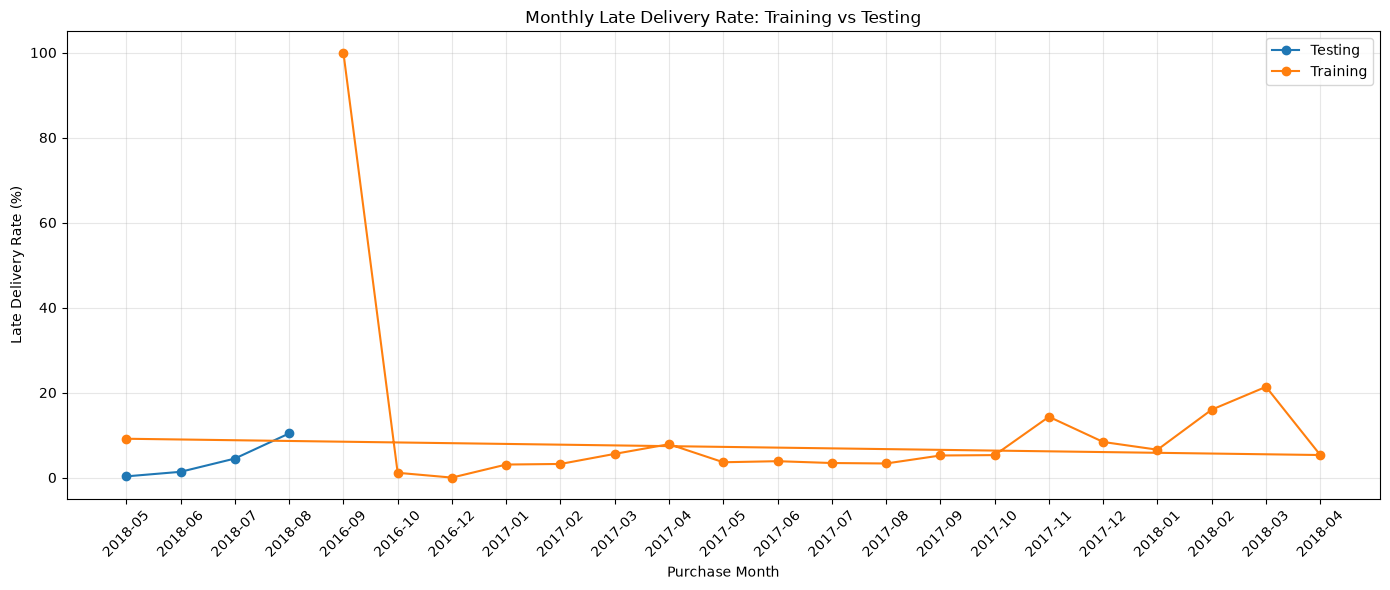

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

for period, group in monthly_period_comparison.groupby(
    "dataset_period"
):
    plt.plot(
        group["year_month"].astype(str),
        group["late_rate"],
        marker="o",
        label=period
    )

plt.title("Monthly Late Delivery Rate: Training vs Testing")
plt.xlabel("Purchase Month")
plt.ylabel("Late Delivery Rate (%)")

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [37]:
# Create a copy of the monthly comparison data
monthly_plot_data = monthly_period_comparison.copy()

# Convert months into real dates
monthly_plot_data["month_date"] = (
    monthly_plot_data["year_month"]
    .dt.to_timestamp()
)

# Sort months chronologically
monthly_plot_data = monthly_plot_data.sort_values(
    "month_date"
)

print("Monthly dates prepared successfully!")

display(monthly_plot_data.head())

Monthly dates prepared successfully!


,year_month,dataset_period,total_orders,late_orders,late_rate,month_date
0,2016-09,Training,1,1,100.00,2016-09-01
1,2016-10,Training,265,3,1.13,2016-10-01
2,2016-12,Training,1,0,0.00,2016-12-01
3,2017-01,Training,750,23,3.07,2017-01-01
4,2017-02,Training,1653,53,3.21,2017-02-01


In [38]:
# Identify training and testing boundary

test_start_date = test_data[
    "order_purchase_timestamp"
].min()

print("Testing period starts:", test_start_date)

Testing period starts: 2018-05-26 18:18:03


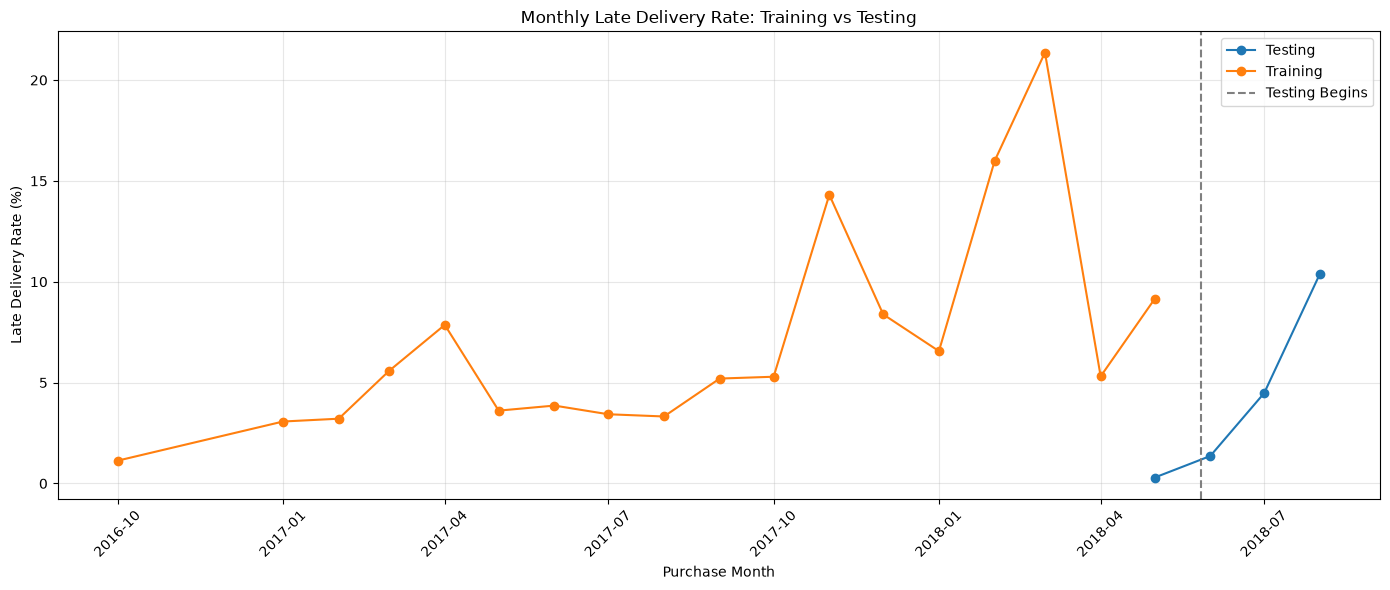

In [39]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Keep months with at least 100 orders in each period
plot_data = monthly_plot_data[
    monthly_plot_data["total_orders"] >= 100
].copy()

plt.figure(figsize=(14, 6))

for period, group in plot_data.groupby("dataset_period"):

    group = group.sort_values("month_date")

    plt.plot(
        group["month_date"],
        group["late_rate"],
        marker="o",
        label=period
    )

# Show training/testing boundary
plt.axvline(
    test_start_date,
    linestyle="--",
    color="gray",
    label="Testing Begins"
)

plt.title("Monthly Late Delivery Rate: Training vs Testing")
plt.xlabel("Purchase Month")
plt.ylabel("Late Delivery Rate (%)")

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter("%Y-%m")
)

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [40]:
# Compare delivery route performance in training and testing

route_period_analysis = model_sorted.copy()

# Label training and testing records
route_period_analysis["period"] = "Testing"

route_period_analysis.loc[
    route_period_analysis.index < split_index,
    "period"
] = "Training"

# Calculate delivery performance
route_period_comparison = (
    route_period_analysis.groupby(
        ["period", "delivery_route"]
    ).agg(
        total_orders=("order_id", "count"),
        late_orders=("late_target", "sum")
    ).reset_index()
)

# Calculate late delivery rates
route_period_comparison["late_rate"] = (
    route_period_comparison["late_orders"]
    / route_period_comparison["total_orders"] * 100
).round(2)

display(route_period_comparison)

,period,delivery_route,total_orders,late_orders,late_rate
0,Testing,Cross State,11535,360,3.12
1,Testing,Same State,7759,661,8.52
2,Training,Cross State,50360,5363,10.65
3,Training,Same State,26816,1442,5.38


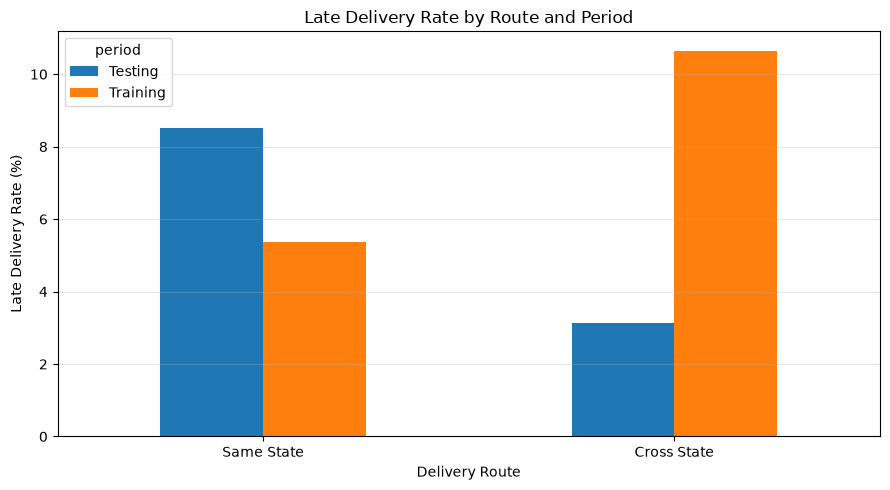

In [41]:
# Compare route performance between periods

comparison_chart = route_period_comparison.pivot(
    index="delivery_route",
    columns="period",
    values="late_rate"
)

ax = comparison_chart.reindex(
    ["Same State", "Cross State"]
).plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Late Delivery Rate by Route and Period")
plt.xlabel("Delivery Route")
plt.ylabel("Late Delivery Rate (%)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [42]:
# Split the original training data into:
# 75% training and 25% validation

validation_split = int(len(train_data) * 0.75)

development_train = train_data.iloc[
    :validation_split
].copy()

validation_data = train_data.iloc[
    validation_split:
].copy()

print("TRAINING AND VALIDATION DATA")
print("----------------------------")

print("Training records:", len(development_train))
print("Validation records:", len(validation_data))
print("Existing test records:", len(test_data))

TRAINING AND VALIDATION DATA
----------------------------
Training records: 57882
Validation records: 19294
Existing test records: 19294


In [43]:
# Check date ranges

for name, dataset in [
    ("Training", development_train),
    ("Validation", validation_data),
    ("Existing Test", test_data)
]:
    print("\n", name)
    print(
        "Start:",
        dataset["order_purchase_timestamp"].min()
    )
    print(
        "End:",
        dataset["order_purchase_timestamp"].max()
    )


 Training
Start: 2016-09-15 12:16:38
End: 2018-03-03 10:06:23

 Validation
Start: 2018-03-03 10:08:51
End: 2018-05-26 18:16:57

 Existing Test
Start: 2018-05-26 18:18:03
End: 2018-08-29 15:00:37


In [44]:
# Compare late-delivery rates across periods

for name, dataset in [
    ("Training", development_train),
    ("Validation", validation_data),
    ("Existing Test", test_data)
]:
    print("\n", name)
    print("Total orders:", len(dataset))
    print("Late orders:", dataset["late_target"].sum())
    print(
        "Late rate:",
        round(dataset["late_target"].mean() * 100, 2),
        "%"
    )


 Training
Total orders: 57882
Late orders: 4563
Late rate: 7.88 %

 Validation
Total orders: 19294
Late orders: 2242
Late rate: 11.62 %

 Existing Test
Total orders: 19294
Late orders: 1021
Late rate: 5.29 %


In [45]:
# Compare same-state and cross-state delivery performance

for name, dataset in [
    ("Training", development_train),
    ("Validation", validation_data)
]:
    print("\n", name.upper())

    summary = dataset.groupby(
        "delivery_route"
    ).agg(
        total_orders=("order_id", "count"),
        late_orders=("late_target", "sum")
    )

    summary["late_rate"] = (
        summary["late_orders"]
        / summary["total_orders"] * 100
    ).round(2)

    display(summary)


 TRAINING


,total_orders,late_orders,late_rate
delivery_route,,,
Cross State,38561,3573,9.27
Same State,19321,990,5.12



 VALIDATION


,total_orders,late_orders,late_rate
delivery_route,,,
Cross State,11799,1790,15.17
Same State,7495,452,6.03


In [46]:
# Select predictor columns
feature_columns = [
    "cross_state_numeric",
    "customer_state",
    "purchase_month"
]

# Training data
X_dev_train = development_train[feature_columns].copy()
y_dev_train = development_train["late_target"].copy()

# Validation data
X_val = validation_data[feature_columns].copy()
y_val = validation_data["late_target"].copy()

# Treat purchase month as a category
X_dev_train["purchase_month"] = (
    X_dev_train["purchase_month"].astype(str)
)

X_val["purchase_month"] = (
    X_val["purchase_month"].astype(str)
)

print("Training features:", X_dev_train.shape)
print("Validation features:", X_val.shape)

print("Training target:", y_dev_train.shape)
print("Validation target:", y_val.shape)

Training features: (57882, 3)
Validation features: (19294, 3)
Training target: (57882,)
Validation target: (19294,)


In [47]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Define categorical predictors
categorical_features = [
    "customer_state",
    "purchase_month"
]

# Create preprocessing
new_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            ["cross_state_numeric"]
        )
    ]
)

# Create new logistic regression pipeline
validation_model = Pipeline(
    steps=[
        ("preprocessing", new_preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

print("Validation model created successfully!")

Validation model created successfully!


In [48]:
# Train on development training data only

validation_model.fit(
    X_dev_train,
    y_dev_train
)

print("New Logistic Regression model trained successfully!")

New Logistic Regression model trained successfully!


In [49]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Generate validation predictions
val_pred = validation_model.predict(X_val)

# Generate probability estimates
val_prob = validation_model.predict_proba(X_val)[:, 1]

print("VALIDATION MODEL RESULTS")
print("------------------------")

print("Accuracy:",
      round(accuracy_score(y_val, val_pred), 4))

print("Precision:",
      round(precision_score(y_val, val_pred, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_val, val_pred, zero_division=0), 4))

print("F1-score:",
      round(f1_score(y_val, val_pred, zero_division=0), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_val, val_prob), 4))

print("Average Precision:",
      round(average_precision_score(y_val, val_prob), 4))

print("\nPredicted late orders:", (val_pred == 1).sum())
print("Actual late orders:", y_val.sum())

VALIDATION MODEL RESULTS
------------------------
Accuracy: 0.8838
Precision: 0.0
Recall: 0.0
F1-score: 0.0
ROC-AUC: 0.6616
Average Precision: 0.2245

Predicted late orders: 0
Actual late orders: 2242


In [50]:
class_weight="balanced"

In [51]:
# Create a class-balanced Logistic Regression model

balanced_model = Pipeline(
    steps=[
        ("preprocessing", new_preprocessor),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=1000
        ))
    ]
)

print("Balanced Logistic Regression pipeline created!")

Balanced Logistic Regression pipeline created!


In [52]:
# Train using development training data only

balanced_model.fit(
    X_dev_train,
    y_dev_train
)

print("Balanced Logistic Regression trained successfully!")

Balanced Logistic Regression trained successfully!


In [53]:
# Predict outcomes using the balanced model

balanced_pred = balanced_model.predict(X_val)

# Predict late delivery probabilities
balanced_prob = balanced_model.predict_proba(X_val)[:, 1]

print("Predictions completed!")

print("Predicted late orders:", (balanced_pred == 1).sum())
print("Actual late orders:", y_val.sum())

Predictions completed!
Predicted late orders: 4595
Actual late orders: 2242


In [54]:
# Evaluate Balanced Logistic Regression

print("BALANCED LOGISTIC REGRESSION RESULTS")
print("------------------------------------")

print("Accuracy:",
      round(accuracy_score(y_val, balanced_pred), 4))

print("Precision:",
      round(precision_score(y_val, balanced_pred, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_val, balanced_pred, zero_division=0), 4))

print("F1-score:",
      round(f1_score(y_val, balanced_pred, zero_division=0), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_val, balanced_prob), 4))

print("Average Precision:",
      round(average_precision_score(y_val, balanced_prob), 4))

BALANCED LOGISTIC REGRESSION RESULTS
------------------------------------
Accuracy: 0.7542
Precision: 0.2279
Recall: 0.467
F1-score: 0.3063
ROC-AUC: 0.6616
Average Precision: 0.2253


In [55]:
# Compare original and balanced validation models

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "Average Precision"
    ],
    "Original Model": [
        accuracy_score(y_val, val_pred),
        precision_score(y_val, val_pred, zero_division=0),
        recall_score(y_val, val_pred, zero_division=0),
        f1_score(y_val, val_pred, zero_division=0),
        roc_auc_score(y_val, val_prob),
        average_precision_score(y_val, val_prob)
    ],
    "Balanced Model": [
        accuracy_score(y_val, balanced_pred),
        precision_score(y_val, balanced_pred, zero_division=0),
        recall_score(y_val, balanced_pred, zero_division=0),
        f1_score(y_val, balanced_pred, zero_division=0),
        roc_auc_score(y_val, balanced_prob),
        average_precision_score(y_val, balanced_prob)
    ]
})

comparison.set_index("Metric").round(4)

,Original Model,Balanced Model
Metric,,
Accuracy,0.8838,0.7542
Precision,0.0000,0.2279
Recall,0.0000,0.4670
F1-score,0.0000,0.3063
ROC-AUC,0.6616,0.6616
Average Precision,0.2245,0.2253


In [56]:
from sklearn.metrics import confusion_matrix

# Calculate balanced model confusion matrix
balanced_cm = confusion_matrix(
    y_val,
    balanced_pred,
    labels=[0, 1]
)

# Extract the four values
tn, fp, fn, tp = balanced_cm.ravel()

print("BALANCED MODEL CONFUSION MATRIX")
print("--------------------------------")

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

BALANCED MODEL CONFUSION MATRIX
--------------------------------
True Negatives: 13504
False Positives: 3548
False Negatives: 1195
True Positives: 1047


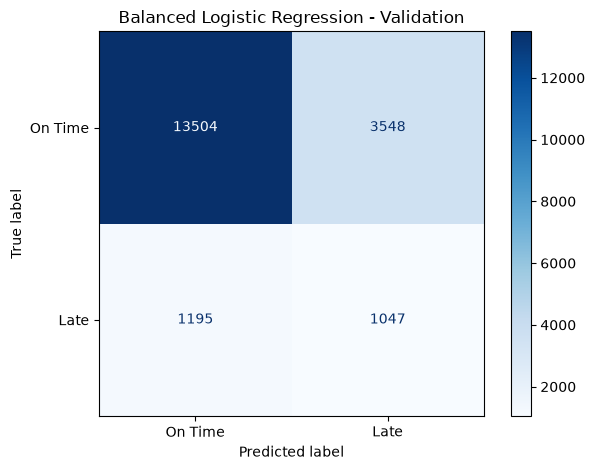

In [57]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create confusion matrix visualization
disp = ConfusionMatrixDisplay(
    confusion_matrix=balanced_cm,
    display_labels=["On Time", "Late"]
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Balanced Logistic Regression - Validation")
plt.tight_layout()
plt.show()

In [58]:
# Calculate alert performance

total_alerts = tp + fp
total_late = tp + fn

print("BUSINESS PERFORMANCE")
print("--------------------")

print("Orders flagged as late:", total_alerts)

print("Actually late among flagged:", tp)

print("False alerts:", fp)

print("Late orders missed:", fn)

print(
    "Alert precision:",
    round(tp / total_alerts * 100, 2),
    "%"
)

print(
    "Late orders detected:",
    round(tp / total_late * 100, 2),
    "%"
)

print(
    "False alerts per correct alert:",
    round(fp / tp, 2) if tp > 0 else "N/A"
)

BUSINESS PERFORMANCE
--------------------
Orders flagged as late: 4595
Actually late among flagged: 1047
False alerts: 3548
Late orders missed: 1195
Alert precision: 22.79 %
Late orders detected: 46.7 %
False alerts per correct alert: 3.39


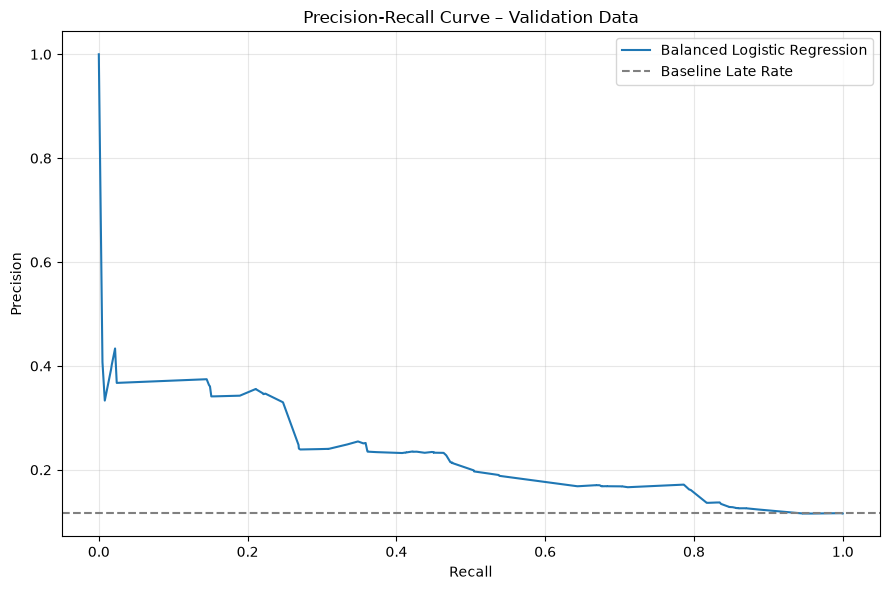

In [59]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

# Calculate precision and recall at different thresholds
precision, recall, thresholds = precision_recall_curve(
    y_val,
    balanced_prob
)

# Create chart
plt.figure(figsize=(9, 6))

plt.plot(
    recall,
    precision,
    label="Balanced Logistic Regression"
)

# Show the baseline late-delivery rate
baseline_rate = y_val.mean()

plt.axhline(
    baseline_rate,
    linestyle="--",
    color="gray",
    label="Baseline Late Rate"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve – Validation Data")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [60]:
# Create a validation risk-ranking table

risk_ranking = pd.DataFrame({
    "order_id": validation_data["order_id"].to_numpy(),
    "actual_late": y_val.to_numpy(),
    "risk_score": balanced_prob
})

# Rank orders from highest to lowest predicted risk
risk_ranking = risk_ranking.sort_values(
    "risk_score",
    ascending=False
).reset_index(drop=True)

# Select the highest-risk 1000 orders
top_1000 = risk_ranking.head(1000)

print("Orders reviewed:", len(top_1000))
print("Actual late orders found:", top_1000["actual_late"].sum())

print(
    "Precision at 1000:",
    round(top_1000["actual_late"].mean() * 100, 2),
    "%"
)

print(
    "Recall at 1000:",
    round(
        top_1000["actual_late"].sum()
        / y_val.sum() * 100,
        2
    ),
    "%"
)

Orders reviewed: 1000
Actual late orders found: 340
Precision at 1000: 34.0 %
Recall at 1000: 15.17 %


In [61]:
# Compare different business review capacities

results = []

for k in [500, 1000, 2000, 5000]:

    selected = risk_ranking.head(k)

    late_found = selected["actual_late"].sum()

    precision_at_k = late_found / k * 100

    recall_at_k = late_found / y_val.sum() * 100

    results.append({
        "Orders_Reviewed": k,
        "Late_Orders_Found": late_found,
        "Precision_Percent": round(precision_at_k, 2),
        "Recall_Percent": round(recall_at_k, 2)
    })

capacity_comparison = pd.DataFrame(results)

display(capacity_comparison)

,Orders_Reviewed,Late_Orders_Found,Precision_Percent,Recall_Percent
0,500,178,35.60,7.94
1,1000,340,34.00,15.17
2,2000,569,28.45,25.38
3,5000,1065,21.30,47.50


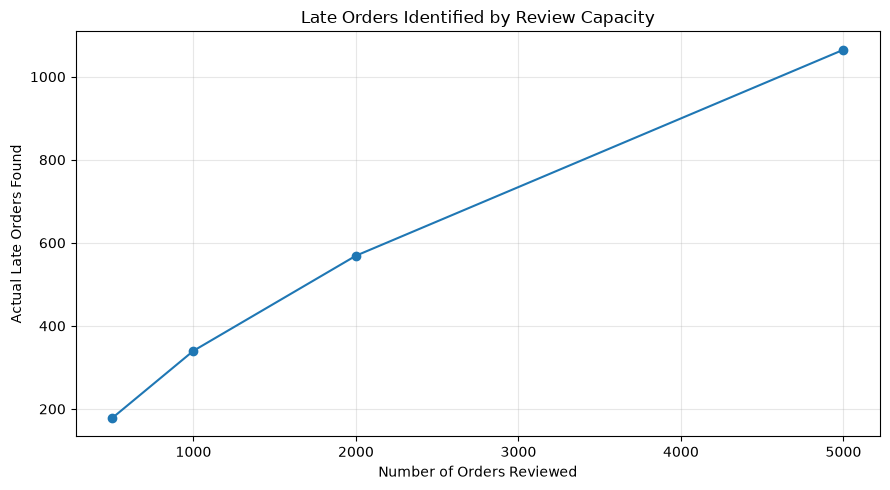

In [62]:
# Visualize review capacity versus late orders found

plt.figure(figsize=(9, 5))

plt.plot(
    capacity_comparison["Orders_Reviewed"],
    capacity_comparison["Late_Orders_Found"],
    marker="o"
)

plt.xlabel("Number of Orders Reviewed")
plt.ylabel("Actual Late Orders Found")

plt.title("Late Orders Identified by Review Capacity")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [63]:
# Calculate the random selection baseline

total_validation_orders = len(y_val)
total_late_orders = y_val.sum()

random_late_rate = total_late_orders / total_validation_orders

print("RANDOM SELECTION BASELINE")
print("-------------------------")

print("Total validation orders:", total_validation_orders)
print("Total late orders:", total_late_orders)

print(
    "Random selection late rate:",
    round(random_late_rate * 100, 2),
    "%"
)

RANDOM SELECTION BASELINE
-------------------------
Total validation orders: 19294
Total late orders: 2242
Random selection late rate: 11.62 %


In [64]:
# Compare model ranking with random selection

business_comparison = capacity_comparison.copy()

business_comparison["Random_Expected_Late"] = (
    business_comparison["Orders_Reviewed"] * random_late_rate
).round(2)

business_comparison["Additional_Late_Found"] = (
    business_comparison["Late_Orders_Found"]
    - business_comparison["Random_Expected_Late"]
).round(2)

business_comparison["Lift"] = (
    business_comparison["Precision_Percent"]
    / (random_late_rate * 100)
).round(2)

display(business_comparison)

,Orders_Reviewed,Late_Orders_Found,Precision_Percent,Recall_Percent,Random_Expected_Late,Additional_Late_Found,Lift
0,500,178,35.60,7.94,58.10,119.90,3.06
1,1000,340,34.00,15.17,116.20,223.80,2.93
2,2000,569,28.45,25.38,232.40,336.60,2.45
3,5000,1065,21.30,47.50,581.01,483.99,1.83


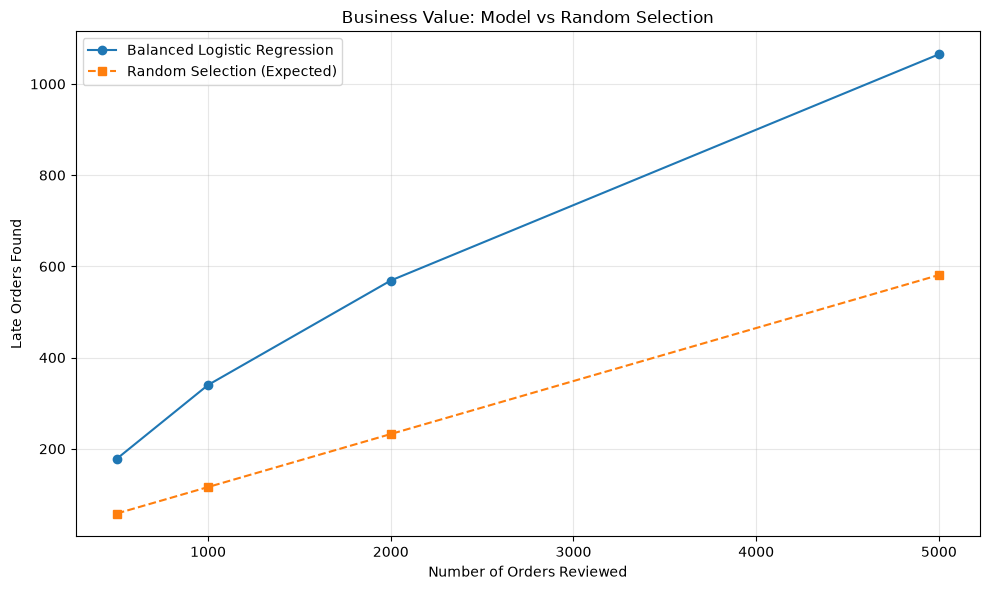

In [65]:
# Compare model with random selection

plt.figure(figsize=(10, 6))

plt.plot(
    business_comparison["Orders_Reviewed"],
    business_comparison["Late_Orders_Found"],
    marker="o",
    label="Balanced Logistic Regression"
)

plt.plot(
    business_comparison["Orders_Reviewed"],
    business_comparison["Random_Expected_Late"],
    marker="s",
    linestyle="--",
    label="Random Selection (Expected)"
)

plt.xlabel("Number of Orders Reviewed")
plt.ylabel("Late Orders Found")

plt.title("Business Value: Model vs Random Selection")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [66]:
# Calculate business value at 1000 reviews

model_late_1000 = top_1000["actual_late"].sum()

random_late_1000 = 1000 * random_late_rate

lift_1000 = model_late_1000 / random_late_1000

print("BUSINESS VALUE AT 1000 REVIEWS")
print("------------------------------")

print("Model late orders found:", model_late_1000)

print(
    "Random expected late orders:",
    round(random_late_1000, 2)
)

print(
    "Additional late orders found:",
    round(model_late_1000 - random_late_1000, 2)
)

print("Lift:", round(lift_1000, 2))

BUSINESS VALUE AT 1000 REVIEWS
------------------------------
Model late orders found: 340
Random expected late orders: 116.2
Additional late orders found: 223.8
Lift: 2.93


### Business Finding: Prioritizing High-Risk Deliveries

**Business Problem**

An e-commerce company may not have enough resources to investigate every customer order. Therefore, identifying potentially late deliveries is important for improving operational efficiency.

**Analytical Approach**

We developed a Logistic Regression model using delivery-route information, customer state, and purchase month. We compared an original model with a class-balanced version and evaluated risk-based order prioritization using historical validation data.

**Key Results**

- The balanced model achieved 46.70% recall and 22.79% precision at its default classification threshold.
- Validation ROC-AUC was approximately 0.6616.
- Reviewing the 1,000 highest-scored orders identified 340 late orders.
- Randomly reviewing 1,000 orders would be expected to identify approximately 116 late orders.
- The model achieved a lift of 2.93× over the random-selection expectation.

**Business Interpretation**

The model demonstrated useful risk-ranking ability during the validation period. It concentrated more late deliveries among the highest-scored orders than random selection.

**Potential Business Recommendation**

A logistics team could investigate a pilot workflow that prioritizes a limited number of high-risk orders for review. The company should evaluate operational costs, false alerts, and whether early interventions can reduce delivery delays before deployment.

**Limitations**

- The analysis uses historical Olist delivery records.
- The model has not been validated as a live operational prediction system.
- Model performance changed considerably across historical periods.
- Prediction probabilities may require calibration.
- The original testing period was examined during development, so a fresh untouched evaluation period would be needed for a stronger final performance claim.